In [ ]:
%pip -q install earthengine-api geemap rasterio requests matplotlib numpy pandas

In [ ]:
import ee, geemap, rasterio, requests, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.ticker import FuncFormatter, MaxNLocator
from rasterio.plot import plotting_extent
from pathlib import Path
from google.colab import output, files
from IPython.display import display

output.enable_custom_widget_manager()
ee.Authenticate()
ee.Initialize(project="ee-project-ntu-512407")

In [ ]:
LON, LAT = -90.15639, 35.06000
RADIUS_M = 5000
BEFORE_YEARS = [2022, 2023]
AFTER_YEARS = [2025, 2026]
MIN_OBSERVATIONS = 2  # Per pixel in EACH summer, not two in the whole period
CRS, SCALE = "EPSG:32615", 30
MAX_UNCERTAINTY_K = None  # Optional sensitivity setting: 3.0
MIN_CLOUD_DISTANCE_KM = None  # Optional sensitivity setting: 0.3
site = ee.Geometry.Point([LON,LAT])
roi = site.buffer(RADIUS_M)
m = geemap.Map(center=[LAT,LON],zoom=13)
m.add_basemap("SATELLITE")
m.addLayer(ee.FeatureCollection([ee.Feature(roi)]).style(
    color="ffff00",fillColor="00000000",width=2),{},"Study radius")
m.addLayer(site,{"color":"cyan"},"Verify approximate Colossus 1 location")
display(m)

Map(center=[35.06, -90.15639], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topri…

In [ ]:
def prepare(im):
    qa = im.select("QA_PIXEL")
    valid = (qa.bitwiseAnd(63).eq(0).And(qa.bitwiseAnd(128).eq(0))
             .And(im.select("QA_RADSAT").eq(0)))
    if MAX_UNCERTAINTY_K is not None:
        valid = valid.And(im.select("ST_QA").multiply(.01).lte(MAX_UNCERTAINTY_K))
    if MIN_CLOUD_DISTANCE_KM is not None:
        valid = valid.And(im.select("ST_CDIST").multiply(.01).gte(MIN_CLOUD_DISTANCE_KM))
    return im.select("ST_B10").multiply(.00341802).add(149).subtract(273.15).rename("LST_C").updateMask(valid)

cx, cy = site.transform(CRS,1).coordinates().getInfo()
# Snap bounds to a shared UTM grid so downloaded years align exactly.
xmin = np.floor((cx-RADIUS_M-300)/SCALE)*SCALE
ymin = np.floor((cy-RADIUS_M-300)/SCALE)*SCALE
xmax = np.ceil((cx+RADIUS_M+300)/SCALE)*SCALE
ymax = np.ceil((cy+RADIUS_M+300)/SCALE)*SCALE
region = ee.Geometry.Rectangle([float(xmin),float(ymin),float(xmax),float(ymax)],
                               proj=CRS,geodesic=False)
grid = [SCALE,0,float(xmin),0,-SCALE,float(ymax)]
width, height = int(round((xmax-xmin)/SCALE)), int(round((ymax-ymin)/SCALE))
arrays, counts, scene_counts = {}, {}, {}
downloaded = []
raster_transform = None

for year in BEFORE_YEARS + AFTER_YEARS:
    collection = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
        .merge(ee.ImageCollection("LANDSAT/LC09/C02/T1_L2"))
        .filterBounds(roi).filterDate(f"{year}-06-01",f"{year}-09-01")
        .filter(ee.Filter.eq("PROCESSING_LEVEL","L2SP")).map(prepare))
    n = collection.size().getInfo()
    scene_counts[year] = n
    print(f"{year}: {n} candidate scenes; downloading summer raster...")
    if n == 0:
        raise ValueError(f"No summer scenes in {year}.")
    count = collection.count().rename("observations").setDefaultProjection(CRS,None,SCALE)
    median = collection.median().setDefaultProjection(CRS,None,SCALE)
    product = (median.updateMask(count.gte(MIN_OBSERVATIONS)).clip(roi)
               .addBands(count.clip(roi)).toFloat().unmask(-9999,False))
    url = product.getDownloadURL({
    "name": f"Colossus_summer_{year}",
    "crs": CRS,
    "crs_transform": grid,
    "dimensions": [width, height],
    "format": "GEO_TIFF",
    "filePerBand": False
    })
    response = requests.get(url,timeout=180)
    response.raise_for_status()
    path = Path(f"Colossus_summer_{year}.tif")
    path.write_bytes(response.content)
    downloaded.append(str(path))
    with rasterio.open(path) as src:
        data = src.read().astype(float)
        data[data == -9999] = np.nan
        if raster_transform is None:
            raster_transform = src.transform
            raster_crs = src.crs
            extent = plotting_extent(src)
            shape = data.shape[1:]
        elif src.transform != raster_transform or data.shape[1:] != shape:
            raise ValueError("Downloaded grids do not align; stop rather than compare different pixels.")
        arrays[year], counts[year] = data[0], data[1]
    print(f"  Pixels meeting the observation minimum: {np.isfinite(arrays[year]).sum():,}")
print("All four years downloaded.")

2022: 12 candidate scenes; downloading summer raster...


  Pixels meeting the observation minimum: 73,150
2023: 11 candidate scenes; downloading summer raster...


  Pixels meeting the observation minimum: 75,979
2025: 10 candidate scenes; downloading summer raster...


  Pixels meeting the observation minimum: 72,574
2026: 12 candidate scenes; downloading summer raster...


  Pixels meeting the observation minimum: 77,640
All four years downloaded.


In [ ]:
common = np.logical_and.reduce([np.isfinite(arrays[y]) for y in BEFORE_YEARS+AFTER_YEARS])
if not common.any():
    raise ValueError("No pixels survive in all four summers. Inspect count rasters and masks before changing thresholds.")
pre = np.where(common,np.mean(np.stack([arrays[y] for y in BEFORE_YEARS]),axis=0),np.nan)
post = np.where(common,np.mean(np.stack([arrays[y] for y in AFTER_YEARS]),axis=0),np.nan)
delta = post-pre
cols, rows = np.meshgrid(np.arange(shape[1])+.5,np.arange(shape[0])+.5)
xs = raster_transform.c + cols*raster_transform.a + rows*raster_transform.b
ys = raster_transform.f + cols*raster_transform.d + rows*raster_transform.e
distance = np.sqrt((xs-cx)**2+(ys-cy)**2)
inside = distance <= RADIUS_M
print(f"Common valid pixels: {common.sum():,}")
print(f"Common coverage of entire study circle: {100*common.sum()/inside.sum():.1f}% (water included in denominator)")
print(f"Raw change range: {np.nanmin(delta):.2f} to {np.nanmax(delta):.2f} °C")

summary=[]
for label,zone in [
    ("0–500 m",distance<=500),
    ("500–1000 m",(distance>500)&(distance<=1000)),
    ("1–3 km",(distance>1000)&(distance<=3000)),
    ("3–5 km",(distance>3000)&(distance<=5000)),
]:
    valid=zone&common
    summary.append({
        "zone":label,"valid_grid_pixels":int(valid.sum()),
        "before_C":float(np.mean(pre[valid])) if valid.any() else np.nan,
        "after_C":float(np.mean(post[valid])) if valid.any() else np.nan,
        "raw_change_C":float(np.mean(delta[valid])) if valid.any() else np.nan,
        "common_coverage_pct":100*valid.sum()/zone.sum() if zone.any() else np.nan
    })
summary=pd.DataFrame(summary)
display(summary.round(2))
summary.to_csv("Colossus_temperature_zone_comparison.csv",index=False)

# A descriptive background-adjusted change can help separate regional change.
# This ring is not a matched causal control.
background = common & (distance>3000) & (distance<=5000)
adjusted = delta-np.mean(delta[background]) if background.any() else np.full_like(delta,np.nan)
if background.any():
    print(f"Background-ring raw change: {np.mean(delta[background]):.2f} °C")
else:
    print("No common background coverage; adjusted-change band will be missing.")

Common valid pixels: 72,197
Common coverage of entire study circle: 82.7% (water included in denominator)
Raw change range: -8.74 to 14.25 °C


,zone,valid_grid_pixels,before_C,after_C,raw_change_C,common_coverage_pct
0,0–500 m,876,37.63,42.15,4.52,100.00
1,500–1000 m,2611,36.16,39.04,2.88,99.92
2,1–3 km,22039,34.55,37.40,2.85,78.96
3,3–5 km,46558,32.34,35.00,2.66,83.31


Background-ring raw change: 2.66 °C


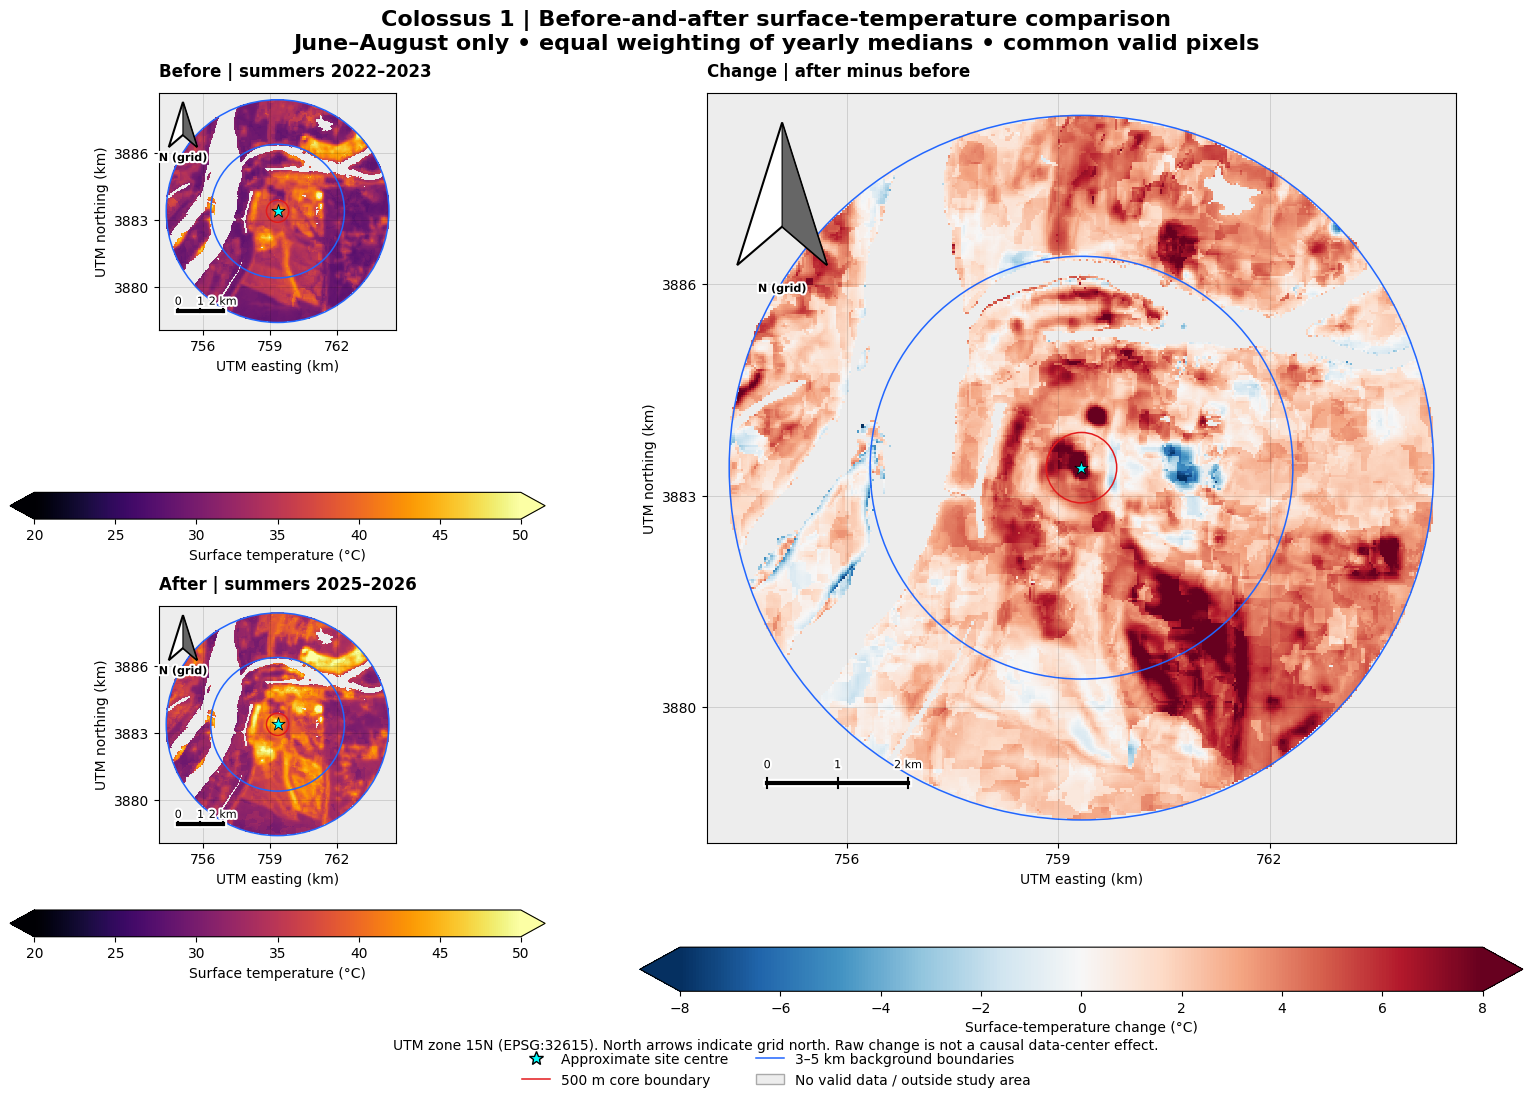

Valid pixels beyond the ±8 °C change color scale: 1.8%
If many values are clipped, increase CHANGE_LIMIT and rerun this plotting cell.


In [ ]:
# Fixed scales allow direct comparisons; colorbar arrows indicate clipping.
TEMP_MIN, TEMP_MAX = 20, 50
CHANGE_LIMIT = 8
def draw_comparison(pre, post, delta, extent, cx, cy, radius):
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    import matplotlib.patheffects as pe
    fig = plt.figure(figsize=(16,11),layout="constrained")
    gs = fig.add_gridspec(2,2,width_ratios=[1,1.65])
    ax_pre = fig.add_subplot(gs[0,0])
    ax_post = fig.add_subplot(gs[1,0])
    ax_change = fig.add_subplot(gs[:,1])
    temp_cmap = plt.get_cmap("inferno").copy()
    change_cmap = plt.get_cmap("RdBu_r").copy()
    temp_cmap.set_bad("#ededed")
    change_cmap.set_bad("#ededed")
    specs = [
        (ax_pre,pre,"Before | summers 2022–2023",temp_cmap,TEMP_MIN,TEMP_MAX,"Surface temperature (°C)"),
        (ax_post,post,"After | summers 2025–2026",temp_cmap,TEMP_MIN,TEMP_MAX,"Surface temperature (°C)"),
        (ax_change,delta,"Change | after minus before",change_cmap,-CHANGE_LIMIT,CHANGE_LIMIT,"Surface-temperature change (°C)")
    ]
    for ax,data,title,cmap,vmin,vmax,label in specs:
        im=ax.imshow(data,extent=extent,origin="upper",cmap=cmap,
                     vmin=vmin,vmax=vmax,interpolation="nearest")
        for ring_radius, ring_color in [(500,"#e31a1c"),(3000,"#2166ff"),(radius,"#2166ff")]:
            ax.add_patch(Circle((cx,cy),ring_radius,fill=False,color=ring_color,linewidth=1.1))
        ax.scatter(cx,cy,marker="*",s=100,facecolor="cyan",edgecolor="black",
                   linewidth=.6,zorder=5)
        ax.set_title(title,loc="left",fontsize=12,weight="bold",pad=12)
        ax.set_aspect("equal")
        ax.set_xlabel("UTM easting (km)")
        ax.set_ylabel("UTM northing (km)")
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos:f"{x/1000:.0f}"))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y,pos:f"{y/1000:.0f}"))
        ax.xaxis.set_major_locator(MaxNLocator(4))
        ax.yaxis.set_major_locator(MaxNLocator(4))
        ax.grid(alpha=.18,color="black",linewidth=.5)
        # This projected UTM map is grid-north up. Label it explicitly.
        halo = [pe.withStroke(linewidth=3, foreground="white")]
        # Black-and-white compass arrow, aligned with UTM grid north.
        from matplotlib.patches import Polygon
        arrow_x, arrow_y = .10, .96
        arrow_w, arrow_h = .12, .19
        tip=(arrow_x,arrow_y)
        left=(arrow_x-arrow_w/2,arrow_y-arrow_h)
        notch=(arrow_x,arrow_y-arrow_h*.73)
        right=(arrow_x+arrow_w/2,arrow_y-arrow_h)
        ax.add_patch(Polygon([tip,left,notch,right],closed=True,
            transform=ax.transAxes,facecolor="white",edgecolor="black",
            linewidth=1.5,zorder=15))
        ax.add_patch(Polygon([tip,notch,right],closed=True,
            transform=ax.transAxes,facecolor="#666666",edgecolor="black",
            linewidth=.8,zorder=16))
        ax.text(arrow_x,arrow_y-arrow_h-.025,"N (grid)",
            transform=ax.transAxes,ha="center",va="top",fontsize=8,
            weight="bold",path_effects=halo,zorder=17)
        # Two-kilometre bar measured in UTM metres, repeated on EVERY panel.
        left,right,bottom,top = extent
        sx, sy = left+.08*(right-left), bottom+.08*(top-bottom)
        bar = ax.plot([sx,sx+2000],[sy,sy],color="black",lw=3,zorder=10)[0]
        bar.set_path_effects([pe.Stroke(linewidth=6,foreground="white"),pe.Normal()])
        for offset, text in [(0,"0"),(1000,"1"),(2000,"2 km")]:
            ax.plot([sx+offset,sx+offset],[sy-70,sy+70],color="black",lw=1.5,zorder=11)
            ax.text(sx+offset,sy+180,text,ha="center",va="bottom",
                    fontsize=8,color="black",path_effects=halo,zorder=11)
        fig.colorbar(im,ax=ax,orientation="horizontal",pad=.07,
                     shrink=.9,extend="both",label=label)
    legend_handles = [
        Line2D([],[],marker="*",linestyle="None",markersize=10,
               markerfacecolor="cyan",markeredgecolor="black",label="Approximate site centre"),
        Line2D([],[],color="#e31a1c",lw=1.1,label="500 m core boundary"),
        Line2D([],[],color="#2166ff",lw=1.1,label="3–5 km background boundaries"),
        Patch(facecolor="#ededed",edgecolor="#aaaaaa",label="No valid data / outside study area")
    ]
    fig.legend(handles=legend_handles,loc="lower center",bbox_to_anchor=(.5,.005),ncol=2,
               frameon=False,fontsize=10)
    fig.suptitle(
        "Colossus 1 | Before-and-after surface-temperature comparison\n"
        "June–August only • equal weighting of yearly medians • common valid pixels",
        fontsize=16,weight="bold")
    fig.supxlabel(
        "UTM zone 15N (EPSG:32615). North arrows indicate grid north. "
        "Raw change is not a causal data-center effect.\n\n\n",
        fontsize=10)
    return fig

fig = draw_comparison(pre,post,delta,extent,cx,cy,RADIUS_M)
fig.savefig("Colossus_temperature_before_after_change.png",dpi=250,bbox_inches="tight")
plt.show()
print(f"Valid pixels beyond the ±{CHANGE_LIMIT} °C change color scale: "
      f"{100*np.mean(np.abs(delta[common])>CHANGE_LIMIT):.1f}%")
print("If many values are clipped, increase CHANGE_LIMIT and rerun this plotting cell.")

In [ ]:
with rasterio.open(
    "Colossus_temperature_comparison.tif","w",driver="GTiff",
    height=shape[0],width=shape[1],count=4,dtype="float32",
    crs=raster_crs,transform=raster_transform,nodata=-9999,compress="deflate"
) as dst:
    for i,(name,data) in enumerate([
        ("before_C",pre),("after_C",post),("raw_change_C",delta),
        ("background_adjusted_change_C",adjusted)],start=1):
        dst.write(np.where(np.isfinite(data),data,-9999).astype("float32"),i)
        dst.set_band_description(i,name)
settings={
    "project":"ee-project-ntu-512407","longitude":LON,"latitude":LAT,
    "radius_m":RADIUS_M,"before_years":BEFORE_YEARS,"after_years":AFTER_YEARS,
    "months":"June–August","minimum_observations_per_year":MIN_OBSERVATIONS,
    "maximum_uncertainty_K":MAX_UNCERTAINTY_K,"minimum_cloud_distance_km":MIN_CLOUD_DISTANCE_KM,
    "crs":CRS,"output_grid_m":SCALE,"candidate_scene_counts":scene_counts,
    "method":"Equal-weight average of yearly summer medians; common valid coverage in all four years",
    "interpretation":"Land-surface temperature, not air temperature; raw change is not causal attribution"
}
Path("Colossus_map_settings.json").write_text(json.dumps(settings,indent=2))
with zipfile.ZipFile("Colossus_temperature_map_results.zip","w",zipfile.ZIP_DEFLATED) as z:
    for filename in downloaded+[
        "Colossus_temperature_before_after_change.png",
        "Colossus_temperature_comparison.tif",
        "Colossus_temperature_zone_comparison.csv",
        "Colossus_map_settings.json"]:
        z.write(filename)
files.download("Colossus_temperature_map_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>